In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [3]:
df=pd.read_csv("train.csv",usecols=["Age","Fare","Survived"])

In [4]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
df.dropna(inplace=True)

In [6]:
x=df.iloc[:,1:]
y=df.iloc[:,0]

In [54]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    random_state=42,
    test_size=0.2
)

In [55]:
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
y_pred=dt.predict(x_test)
accuracy_score(y_test,y_pred)

0.6503496503496503

In [56]:
np.mean(cross_val_score(DecisionTreeClassifier(),x,y,cv=10,scoring="accuracy"))

np.float64(0.6316901408450704)

In [57]:
kbin_age=KBinsDiscretizer(n_bins=10,encode="ordinal",strategy="quantile")
kbin_fare=KBinsDiscretizer(n_bins=10,encode="ordinal",strategy="quantile")

In [58]:
trf=ColumnTransformer(
    [
        ("first",kbin_age,[0]),
        ("second",kbin_fare,[1])
    ]
)

In [59]:
x_train_trf=trf.fit_transform(x_train)
x_test_trf=trf.fit_transform(x_test)

In [60]:
trf.named_transformers_['first'].n_bins

10

In [61]:
trf.named_transformers_['second'].bin_edges_

array([array([  0.    ,   7.7417,   7.925 ,   8.6625,  10.5   ,  14.4542,
               22.525 ,  29.125 ,  39.    ,  57.9792, 512.3292])         ],
      dtype=object)

In [62]:
output=pd.DataFrame({
    "age": x_train["Age"],
    "age_trf": x_train_trf[:,0],
    "fare": x_train["Fare"],
    "fare_trf": x_train_trf[:,1]
        }    
)

In [63]:
output.head()

,age,age_trf,fare,fare_trf
328,31.0,5.0,20.5250,5.0
73,26.0,4.0,14.4542,4.0
253,30.0,5.0,16.1000,5.0
719,33.0,6.0,7.7750,1.0
666,25.0,4.0,13.0000,4.0


In [64]:
output["age_label"]=pd.cut(x=x_train["Age"],
                         bins=trf.named_transformers_["first"].bin_edges_[0].tolist())
output["fare_label"]=pd.cut(x=x_train["Fare"],
                         bins=trf.named_transformers_["second"].bin_edges_[0].tolist())

In [65]:
output.head()

,age,age_trf,fare,fare_trf,age_label,fare_label
328,31.0,5.0,20.5250,5.0,"(30.0, 35.0]","(14.454, 22.525]"
73,26.0,4.0,14.4542,4.0,"(24.0, 28.0]","(10.5, 14.454]"
253,30.0,5.0,16.1000,5.0,"(28.0, 30.0]","(14.454, 22.525]"
719,33.0,6.0,7.7750,1.0,"(30.0, 35.0]","(7.742, 7.925]"
666,25.0,4.0,13.0000,4.0,"(24.0, 28.0]","(10.5, 14.454]"


In [66]:
clf=DecisionTreeClassifier()
clf.fit(x_train_trf,y_train)
y_pred2=clf.predict(x_test_trf)
accuracy_score(y_test,y_pred2)

0.6853146853146853

### As we can see here the results are improved a little after Binning

In [70]:
x_trf=trf.fit_transform(x)
np.mean(cross_val_score(DecisionTreeClassifier(),x_trf,y,scoring="accuracy",cv=10))

np.float64(0.6807316118935838)

In [88]:
def discrete(bins,method):
    kbin=KBinsDiscretizer(n_bins=bins,strategy=method,encode="ordinal")
    trf1=ColumnTransformer([
        ("first",kbin,[0]),
        ("second",kbin,[1]),
    ],remainder="passthrough")
    
    x_train_trf1=trf.fit_transform(x_train)
    x_test_trf1=trf.fit_transform(x_test)
    
    clf=DecisionTreeClassifier()
    clf.fit(x_train_trf1,y_train)
    y_pred3=clf.predict(x_test_trf1)
    print(f"Accuracy: {accuracy_score(y_test,y_pred3)}")
    
    x_trf1=trf1.fit_transform(x)
    print(f"cross_val_score: {np.mean(cross_val_score(DecisionTreeClassifier(),x_trf1,y,scoring="accuracy",cv=10))} ")
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(x_train["Fare"])
    plt.title("before")

    plt.subplot(122)
    plt.hist(x_trf1[:,1],color='red')
    plt.title("After discretization")

    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(x_train["Age"])
    plt.title("before")

    plt.subplot(122)
    plt.hist(x_trf1[:,0],color='red')
    plt.title("After discretization")

Accuracy: 0.6853146853146853
cross_val_score: 0.6807316118935838 


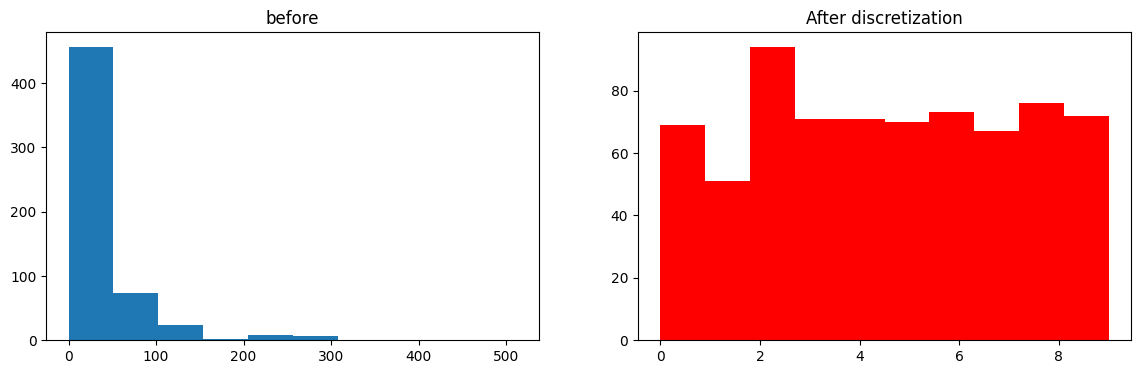

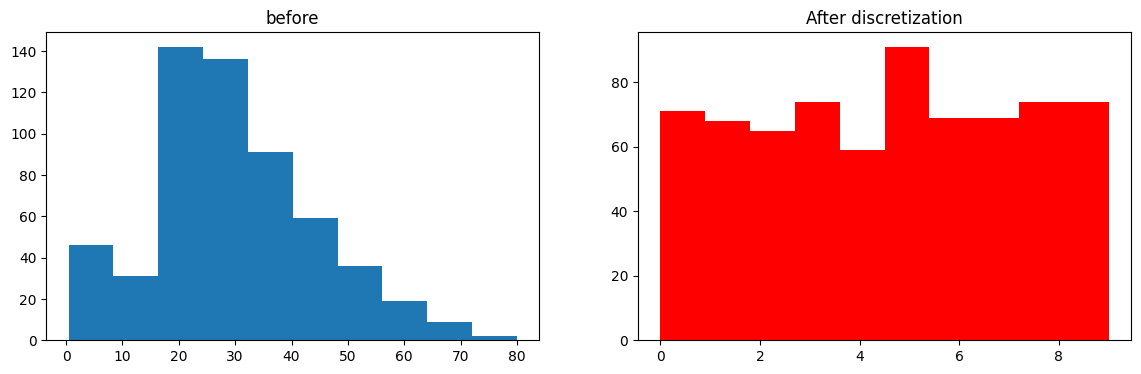

In [89]:
discrete(10,"quantile")

### As we can see the spread of data has become uniform here and get a good accuracy than normal x_train

Accuracy: 0.6853146853146853
cross_val_score: 0.6864632237871675 


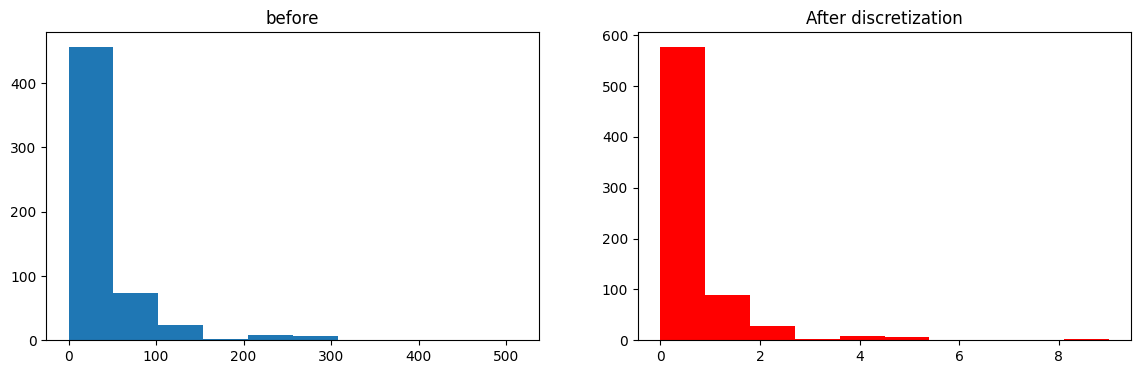

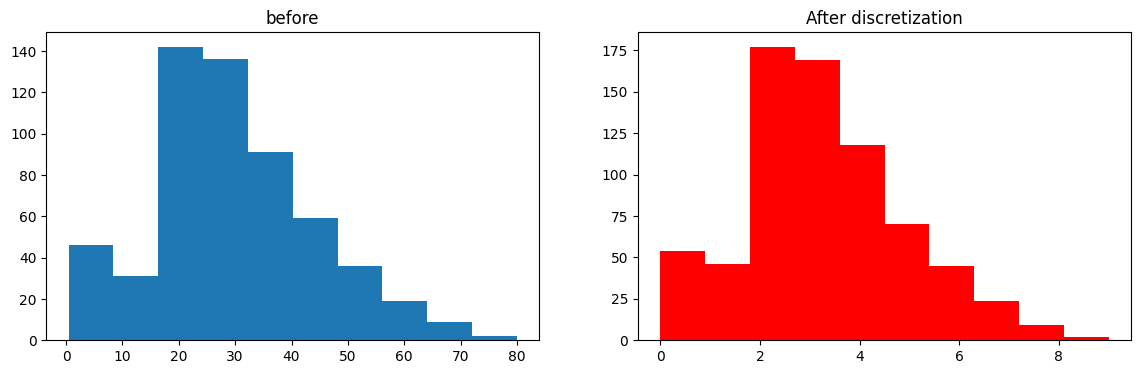

In [90]:
discrete(10,"uniform")

### As we can see the above graph the data spread is same as before but the accuracy is increased (depends on data also so apply every binning method to check which is good)

Accuracy: 0.6853146853146853
cross_val_score: 0.6584702660406886 


C:\Users\prana\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\prana\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


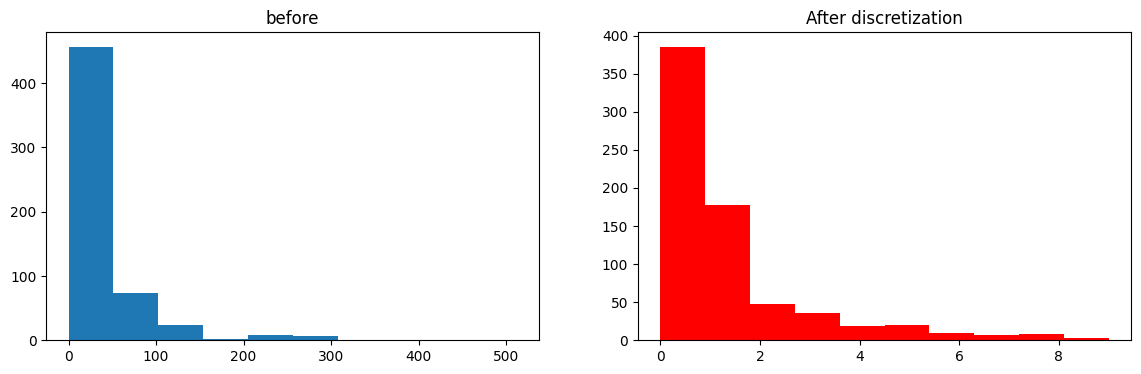

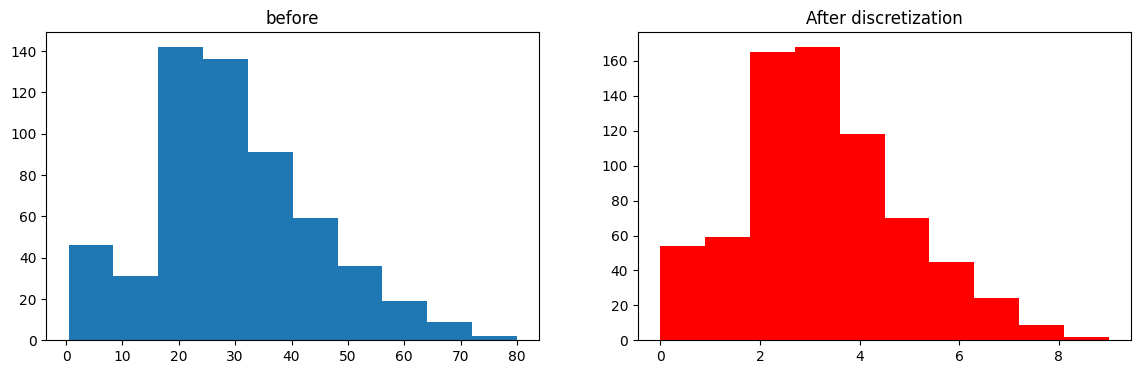

In [91]:
discrete(10,"kmeans")

### Here we see the dataspread is same as before binning and the accuracy is much lesser for this data 